In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import ipywidgets as widgets
from ipywidgets import interact, Dropdown, IntSlider, FloatSlider
from IPython.display import display

from scipy import stats

In [47]:
df = pd.read_csv('/content/sample_data/superstore.csv', encoding='latin-1')

**1. Data Preparation:**

Download and explore the US Superstore data.
Perform basic data cleaning and preprocessing.

In [48]:
# checking for duplicates: - None:
df.duplicated().sum()

np.int64(0)

In [49]:
# basic info:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [50]:
df.head(3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


In [51]:
# as neither duplicate nor missing values present, we don't need to drop or fill in
# but we need to transform to datetime the dates columns and add a year column for the order
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['order_year'] = df['Order Date'].dt.year

**2. Data Visualization with Matplotlib:**

- Create an interactive line chart to show sales trends over the years.
- Build an interactive map to visualize sales distribution by country.

In [53]:
def sales_trend(agg_level='All', agg_loc='All data selected'):
  # Start with the main dataframe
  filtered_df = df.copy()

  # Apply location filtering if selected
  if agg_level == 'State' and agg_loc != 'All data selected':
    filtered_df = filtered_df[filtered_df['State'] == agg_loc]
  elif agg_level == 'City' and agg_loc != 'All data selected':
    filtered_df = filtered_df[filtered_df['City'] == agg_loc]

  # Aggregate sales by year
  sales_vector = filtered_df.groupby('order_year')[['Sales', 'Profit']].sum().reset_index()

  # If the filter results in no data, display a message
  if sales_vector.empty:
    print(f"No data found for {agg_level}: {agg_loc}")
    return

  plt.figure(figsize=(8, 5))
  sns.lineplot(x='order_year', y='Sales', data=sales_vector, marker='o')
  plt.title(f'Sales Trend Over The Years ({agg_level}: {agg_loc})')
  plt.xlabel('Year')
  plt.ylabel('Sales')
  plt.xticks(sales_vector['order_year'])
  plt.grid(True, linestyle='--', alpha=0.5)
  plt.show()

# Underlying data lists
states_list = sorted(df['State'].unique().tolist())
cities_list = sorted(df['City'].unique().tolist())

# Data map lookup
data_map = {
    'All': ['All data selected'],
    'State': states_list,
    'City': cities_list
}

# First dropdown (d1)
d1 = Dropdown(
    options=['All', 'State', 'City'],
    value='All',
    description='Level:'
)

# Second dropdown (d2)
d2 = Dropdown(
    options=data_map[d1.value],
    value='All data selected',
    description='Location:',
    disabled=True
)

# Update handler function to update d2 options depending on d1 selection
def on_d1_change(change):
    selected_level = change['new']
    d2.options = data_map[selected_level]
    d2.value = data_map[selected_level][0]
    d2.disabled = (selected_level == 'All')

# Bind the function to monitor value changes in d1
d1.observe(on_d1_change, names='value')

# Render the interactive plot
interact(sales_trend, agg_level=d1, agg_loc=d2)

interactive(children=(Dropdown(description='Level:', options=('All', 'State', 'City'), value='All'), Dropdown(…

<function __main__.sales_trend(agg_level='All', agg_loc='All data selected')>

In [66]:
# interactive map to visualize distribution by state
# histogram plot to visualize profit margin distribution:
state_sales = df.groupby('State')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False).reset_index()
#state_sales['profit_margin'] = state_sales['Profit'] / state_sales['Sales']

def dynamic_hist(bin_count=10):
  # Ensure bin_count is at least 1 to prevent negative or zero bins
  bin_count = max(1, bin_count)
  ax = sns.histplot(data=state_sales, x='Sales', bins=bin_count)
  xticks = ax.get_xticks()
  ax.set_xticks(xticks) # Keeps current tick locations
  ax.set_xticklabels([f"${y/1000:,.0f}K" for y in xticks])
  ax.set_xlim(left=0)
  plt.show()

# Defining the slider with a strict min value of 1 to prevent negative values
slider = IntSlider(value=10, min=1, max=len(df['State'].unique()), step=1, description='number of bins: ')

# Connect slider parameter 'bin_count' to match dynamic_hist's parameter name
interact(dynamic_hist, bin_count=slider)

interactive(children=(IntSlider(value=10, description='number of bins: ', max=49, min=1), Output()), _dom_clas…

<function __main__.dynamic_hist(bin_count=10)>

**3. Data Visualization with Seaborn**:

- Use Seaborn to generate a bar chart showing top 10 products by sales.
- Create a scatter plot to analyze the relationship between profit and discount.

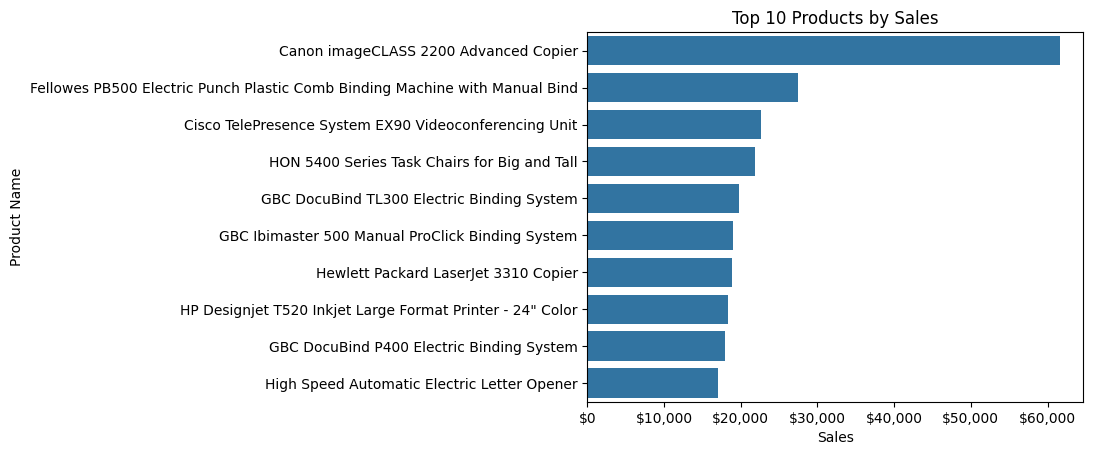

In [76]:
# bar chart for top 10 products by sales
ax = sns.barplot(x='Sales', y='Product Name', data=df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).reset_index().head(10))
ax.set_xlabel('Sales')
ax.set_ylabel('Product Name')
ax.set_title('Top 10 Products by Sales')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.set_ylabel('Product Name')
plt.show()

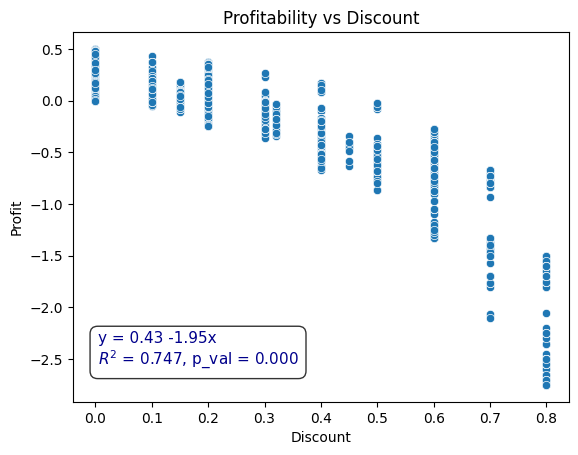

In [73]:
# scatter plot for profitability vs discount - on transaction_level
df['profit_margin'] = df['Profit'] / df['Sales']
ax = sns.scatterplot(x='Discount', y='profit_margin', data=df)
ax.set_xlabel('Discount')
ax.set_ylabel('Profit')
ax.set_title('Profitability vs Discount')

# Add regression equation:
reg_result = stats.linregress(df['Discount'], df['profit_margin'])
equation_text = f"y = {reg_result.intercept:.2f} {reg_result.slope:.2f}x \n$R^2$ = {reg_result.rvalue**2:.3f}, p_val = {reg_result.pvalue:.3f}"

# Regression eq overlay onto the chart
ax.text(0.05, 0.10, equation_text, transform=ax.transAxes,
        fontsize=11, color="darkblue",
        bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

plt.show()

highly singificant negative linear relationship between discount provided on the ourchase and its profitability. Per addition 1% discount, the profitability of the purchase for the supermarket decreases by almost 2%

**4. Comparative Analysis:**

Compare the insights gained from Matplotlib and Seaborn visualizations. Document your observations about the ease of use and effectiveness of both tools.

A:
- protiability is singificantly negatively impacted by the descounts offered
- most revenue generating products are in electronics
- revenue groth ove the years on average, but declien in certain locations
- very useful visualizations via both backages matplotlib and seaborn